# Vertex Component Analysis (VCA)

*Reference: J. M. P. Nascimento and J. M. Bioucas-Dias, *Vertex component analysis: a fast algorithm to unmix hyperspectral data*, IEEE Transactions on Geoscience and Remote Sensing, 43(4):898-910, 2005.*

### Model

Let $Y \in \mathbb{R}_+^{L \times N}$ be a set of hyperspectral observations ($L$ bands, $N$ pixels), $M \in \mathbb{R}^{L \times K}$ the endmembers and $A \in \mathbb{R}_+^{K \times N}$ the abundances. The algorithm relies on the linear mixing model

$$
Y \approx MA ,
$$

where each pixel is a convex combination of the $K$ endmembers: the abundances are non-negative and sum to one. Geometrically, the pixels lie in the simplex whose vertices are the endmembers.

**Pure-pixel assumption.** For each endmember $m_k$ there is at least one pixel $y_n = m_k$. The endmembers are then the vertices of the simplex spanned by the data, and the algorithm has only to find the $K$ most extreme pixels. It cannot return a vertex that is not associated with an observed pixel: when no pixel is pure, the estimate is therefore biased towards the interior of the simplex.

### Algorithm

VCA uses the fact that the vertices of a simplex stay its vertices under any affine transform, and that the maximum of the projection of a simplex onto any direction is reached at a vertex.

1. **Subspace projection.** The signal-to-noise ratio is estimated. Above the threshold $15 + 10 \log_{10} K$ dB, the data is projected onto its $K$-dimensional signal subspace (SVD, without centering), then each pixel is rescaled by a perspective projection $x_n \leftarrow x_n / (x_n^\top u)$, with $u$ the mean of the projected data. Below the threshold, the data is projected onto a $(K-1)$-dimensional PCA subspace and a constant coordinate is appended.
2. **Iterative vertex extraction.** For $k = 1, \dots, K$:
   * a direction $w$ is drawn uniformly in $[0, 1]^K$ and made orthogonal to the vertices already selected (the first one to the last axis): $f = (I - E E^{+})\, w$, where the columns of $E$ are the selected vertices;
   * the selected pixel is the one with the largest projection on $f$ in absolute value, $n_k = \arg\max_n |f^\top x_n|$.
3. **Endmembers.** As in the reference MATLAB code, the endmembers are the selected pixels projected onto the signal subspace, i.e. denoised. The raw pixels are `Y[:, model.indices_]`.

### Randomness

The only source of randomness is the choice of the projection directions, set by `SEED`.

### Abundances

The algorithm only estimates the endmembers. The abundances are computed afterwards by fully constrained least squares (FCLS), pixel by pixel:

$$
A = \operatorname*{arg\,min}_{A \ge 0,\; \mathbf{1}_K^\top A = \mathbf{1}_N^\top} \lVert Y - MA \rVert_F^2 .
$$

`model.estimate_abundances(Y)` stores them in `abundances_` (and, when the model stores its initialization, the abundances of `endmembers_init_` in `abundances_init_`), so that the model can be passed to `UnmixingEvaluation.add_model`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

import time

import numpy as np

from src.utils.dataset import *
from src.utils.metrics import UnmixingEvaluation

from src.geometric import VCA

## 1. Samson

In [2]:
# Load the dataset
HSI_path = "src/dataset/samson.npz"
HSI = HyperspectralData.load_npz(HSI_path)
n_endmembers = HSI.n_endmembers
normalized_observation, scale_factor = HSI.normalized_observations
normalized_observation = np.maximum(normalized_observation, 0)
image_shape = HSI.image_shape

### Fitting the algorithm

The randomness is set by `SEED`.

In [3]:
SEED = 0

model = VCA(
    n_endmembers=n_endmembers,
    rng=np.random.default_rng(SEED),
)
start = time.perf_counter()
model.fit(normalized_observation)
print(f"Fitted in {time.perf_counter() - start:.1f} s")

# The algorithm only estimates the endmembers: abundances by FCLS
model.estimate_abundances(normalized_observation)

evaluation = UnmixingEvaluation(HSI.endmembers, HSI.abundances, names=HSI.names)
evaluation.add_model("VCA", model, scale=scale_factor);

Fitted in 0.2 s


### Endmember and abundance evaluation

Each estimate is matched to the ground truth (Hungarian algorithm on the SAD) and its abundances are aligned with the same permutation.

In [4]:
evaluation.display()

Spectral Angle Distance (SAD) - lower is better


,#1 Soil,#2 Tree,#3 Water,Mean
VCA,0.0610,0.0495,0.1299,0.0801


Mean Squared Error (MSE) on min-max normalized spectra - lower is better


,#1 Soil,#2 Tree,#3 Water,Mean
VCA,0.0011,0.0003,0.0042,0.0019


Mean Squared Error (MSE) on raw spectra - lower is better


,#1 Soil,#2 Tree,#3 Water,Mean
VCA,0.0761,0.0268,0.2587,0.1205


Standardized cross-correlation (SCC) - higher is better


,#1 Soil,#2 Tree,#3 Water,Mean
VCA,0.9982,0.9994,0.9800,0.9925


Abundance errors - lower is better (SCC: higher is better)


,MSE,RMSE,MAE,SAM,SCC
VCA,0.0538,0.2319,0.1574,0.3757,0.8917


### Endmember spectra

Estimated and ground-truth spectra, min-max normalized, after matching.

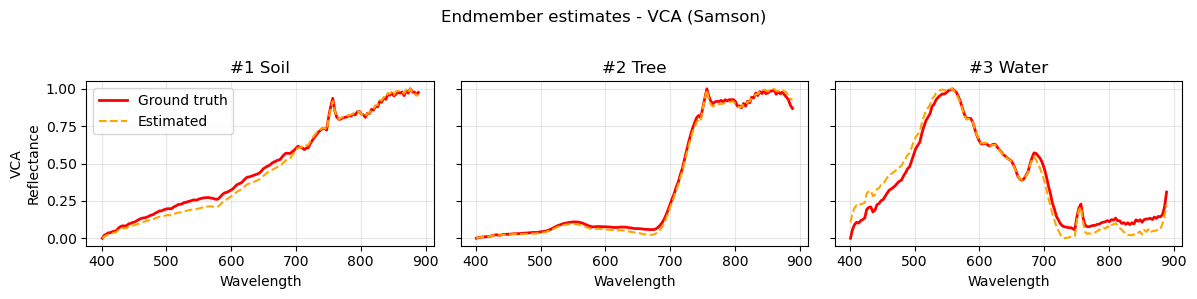

In [5]:
fig, axes = evaluation.plot_endmembers(
    HSI.wavelengths,
    band=None,
    title="Endmember estimates - VCA (Samson)",
)

### Abundance maps

Ground-truth and aligned estimated abundance maps.

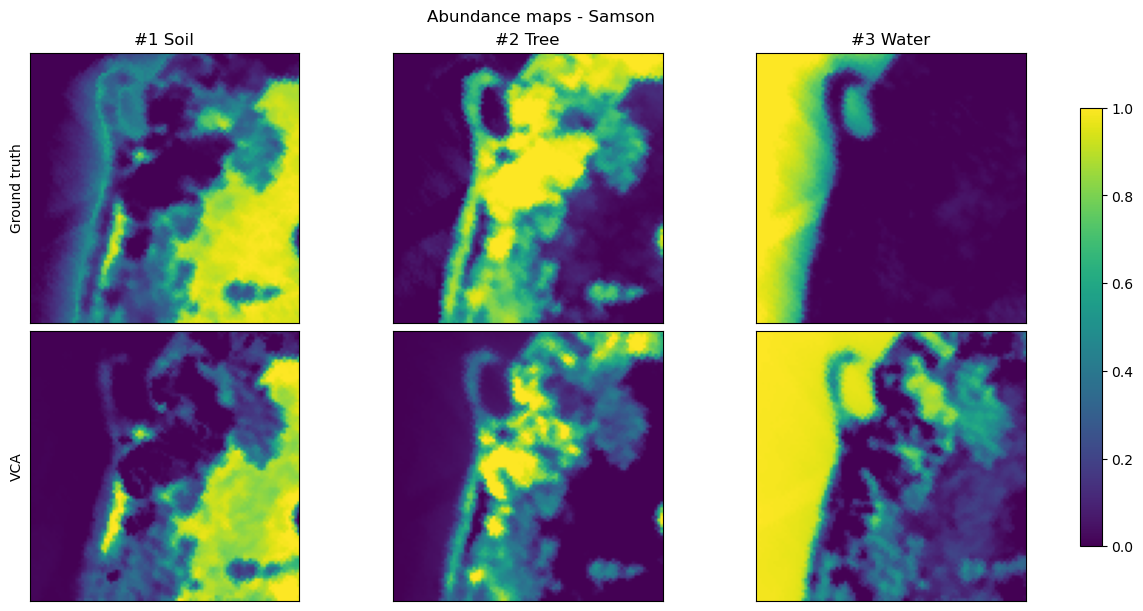

In [6]:
# Abundance maps (only for datasets with a spatial structure)
if image_shape is not None:
    fig, axes = evaluation.plot_abundances(image_shape, title="Abundance maps - Samson")

## 2. Jasper Ridge

In [7]:
# Load the dataset
HSI_path = "src/dataset/jasper_ridge.npz"
HSI = HyperspectralData.load_npz(HSI_path)
n_endmembers = HSI.n_endmembers
normalized_observation, scale_factor = HSI.normalized_observations
normalized_observation = np.maximum(normalized_observation, 0)
image_shape = HSI.image_shape

### Fitting the algorithm

The randomness is set by `SEED`.

In [8]:
SEED = 0

model = VCA(
    n_endmembers=n_endmembers,
    rng=np.random.default_rng(SEED),
)
start = time.perf_counter()
model.fit(normalized_observation)
print(f"Fitted in {time.perf_counter() - start:.1f} s")

# The algorithm only estimates the endmembers: abundances by FCLS
model.estimate_abundances(normalized_observation)

evaluation = UnmixingEvaluation(HSI.endmembers, HSI.abundances, names=HSI.names)
evaluation.add_model("VCA", model, scale=scale_factor);

Fitted in 0.3 s


### Endmember and abundance evaluation

Each estimate is matched to the ground truth (Hungarian algorithm on the SAD) and its abundances are aligned with the same permutation.

In [9]:
evaluation.display()

Spectral Angle Distance (SAD) - lower is better


,#1 Tree,#2 Water,#3 Soil,#4 Road,Mean
VCA,0.1769,0.2643,0.2264,1.0868,0.4386


Mean Squared Error (MSE) on min-max normalized spectra - lower is better


,#1 Tree,#2 Water,#3 Soil,#4 Road,Mean
VCA,0.0116,0.0041,0.0206,0.3479,0.0960


Mean Squared Error (MSE) on raw spectra - lower is better


,#1 Tree,#2 Water,#3 Soil,#4 Road,Mean
VCA,0.0188,0.0008,0.0514,0.1774,0.0621


Standardized cross-correlation (SCC) - higher is better


,#1 Tree,#2 Water,#3 Soil,#4 Road,Mean
VCA,0.9849,0.9907,0.8255,-0.5609,0.5601


Abundance errors - lower is better (SCC: higher is better)


,MSE,RMSE,MAE,SAM,SCC
VCA,0.1496,0.3867,0.2140,0.6830,0.4551


### Endmember spectra

Estimated and ground-truth spectra, min-max normalized, after matching.

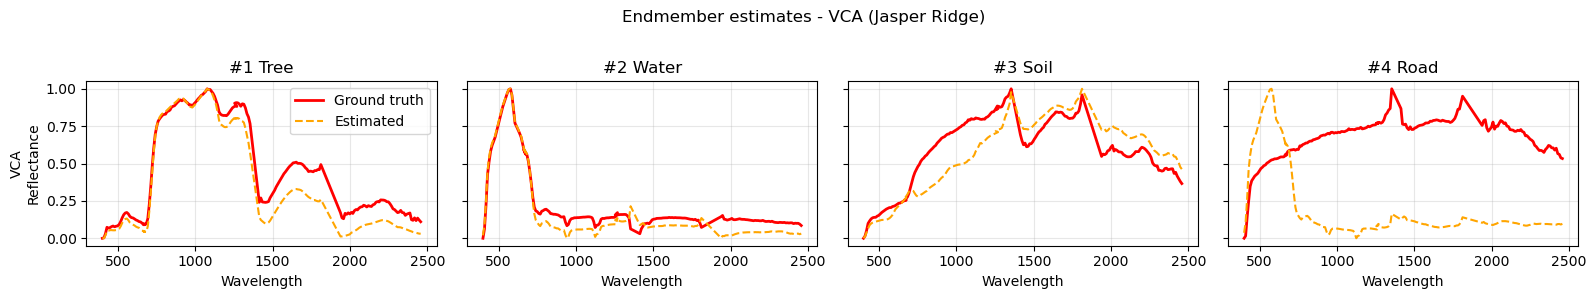

In [10]:
fig, axes = evaluation.plot_endmembers(
    HSI.wavelengths,
    band=None,
    title="Endmember estimates - VCA (Jasper Ridge)",
)

### Abundance maps

Ground-truth and aligned estimated abundance maps.

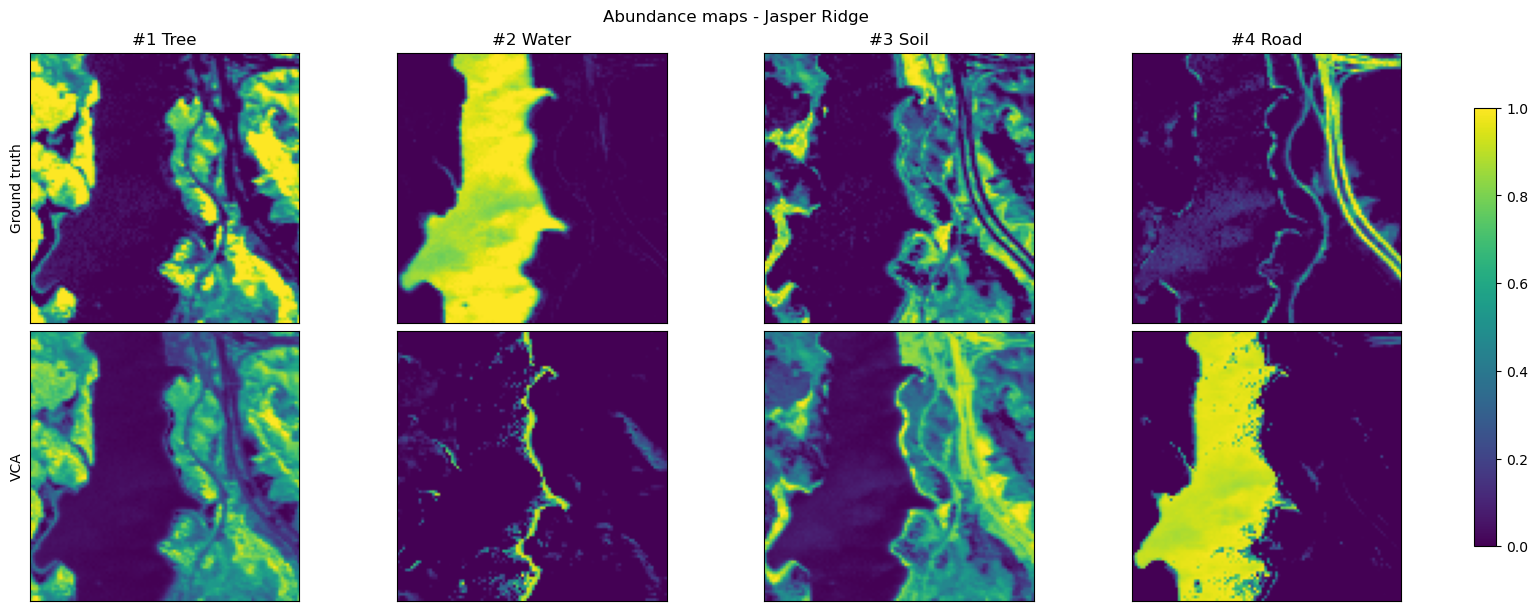

In [11]:
# Abundance maps (only for datasets with a spatial structure)
if image_shape is not None:
    fig, axes = evaluation.plot_abundances(image_shape, title="Abundance maps - Jasper Ridge")